# Regression in scikit-learn

This notebook complements the regression chapter with a stronger **hands-on emphasis**:
we compare several regressors on the same task, compute one error measure **by hand**,
and visualize the behavior of both **default** and **tuned** models.

We use a simple age-height dataset so that the fitted functions can be inspected directly.


## What this notebook emphasizes

- A **constant baseline** for regression by hand and with scikit-learn
- Computing error with **MSE** by hand and with scikit-learn
- Comparing the behavior of **different regression models** on the same task
- A **default regression tree overfits**
- **Hyperparameter tuning** is part of the workflow for trees, KNN, and polynomial degree
- **Pipelines** are useful for chaining transformations and models together
- The same model can behave differently when the **representation changes**
- Train-test split is important for **model selection** and **model evaluation**
- Note: Specific imports are placed near the section where they are used.


In [16]:
# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42


In [17]:
# Aesthetics and custom style for the notebook

try:
    from mlbook_style import apply_style, COLORS, ALIASES, pale, get_color, savefig
    apply_style()
except ImportError:
    print("Custom style not found. Using default matplotlib settings.")
    COLORS = {}
    ALIASES = {}
    def pale(color, alpha=0.45):
        return color
    def get_color(name, tuned=True, alpha_light=0.45):
        return None

pd.options.display.float_format = '{:.2f}'.format

## Load the data

The notebook first looks for a local CSV file.  
If none is found, it generates a synthetic age--height dataset with the same qualitative pattern:
rapid growth early in life and leveling off later.


In [18]:
from pathlib import Path    

def make_synthetic_age_height(n=220, seed=42):
    rng = np.random.default_rng(seed)
    age = np.sort(rng.uniform(0, 95, size=n))

    base = 50 + 125 * (1 - np.exp(-age / 11.0))
    noise = rng.normal(0, 4 + 0.08 * age, size=n)
    height = np.clip(base + noise, 45, 200)

    gender = rng.choice(["female", "male"], size=n, p=[0.5, 0.5])
    height = height + np.where((age > 11) & (gender == "male"), 4.0, 0.0)

    return pd.DataFrame({"Age": age, "Height": height, "Gender": gender})

candidate_files = [
    Path("./age-height.csv"),
    Path("./age_height.csv"),
]

for path in candidate_files:
    if path.exists():
        csv_file_path = path
        break

if csv_file_path is not None:
    df = pd.read_csv(csv_file_path)
    print(f"Loaded data from: {csv_file_path}")
else:
    df = make_synthetic_age_height(n=220, seed=RANDOM_STATE)
    print("No local CSV found. Using a synthetic age-height dataset.")

print("Data shape:", df.shape)
display(df.head())


Loaded data from: age-height.csv
Data shape: (200, 3)


,Age,Gender,Height
0,0.00,M,54
1,0.00,F,49
2,0.10,M,55
3,0.10,F,53
4,0.20,M,57


**Check.** Which column is the target in this notebook?

<details>
<summary>Answer</summary>

The target is `Height`. The input feature in the first part of the notebook is `Age`. We will later use `Gender` as an additional input feature.

</details>


## Input and output, train-test split

We use the same split for all models so that performance numbers are directly comparable.


Training examples: 160
Test examples: 40


count   160.00
mean    143.59
std      40.82
min      49.00
25%     114.00
50%     160.50
75%     174.00
max     194.00
Name: Height, dtype: float64

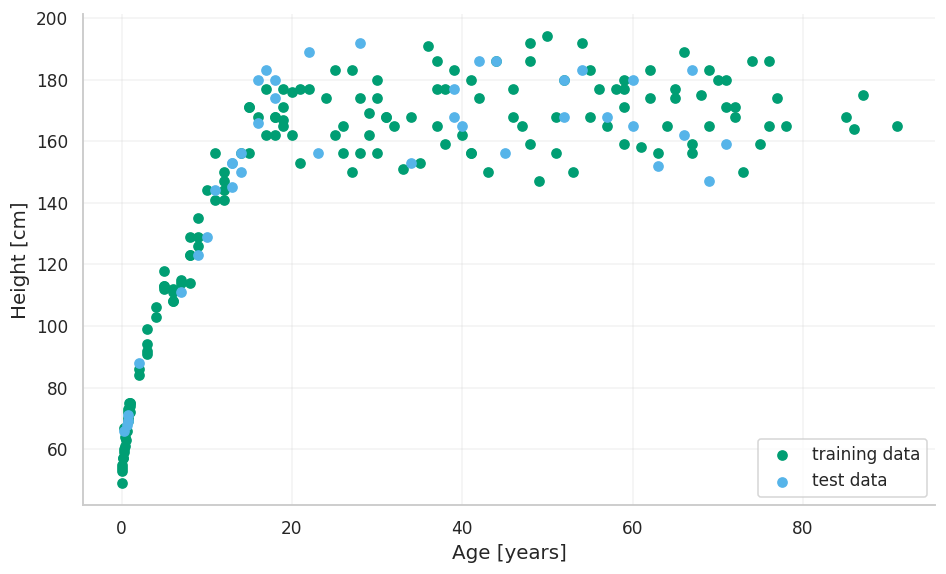

In [19]:
from sklearn.model_selection import train_test_split

feature_cols = ["Age"]
target_col = "Height"

X = df[feature_cols]
y = df[target_col]

# 20% of the data will be used for testing, and the rest for training
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

# For visualization, we create a grid of age values spanning the range of the training data
X_viz = pd.DataFrame({"Age": np.linspace(0, 100, 101)})

print("Training examples:", len(X_train))
print("Test examples:", len(X_test))
display(y_train.describe())

plt.figure()
plt.scatter(X_train["Age"], y_train, label="training data", color=ALIASES.get("actual", None))
plt.scatter(X_test["Age"], y_test, label="test data", color=ALIASES.get("test", None))
plt.xlabel("Age [years]")
plt.ylabel("Height [cm]")
plt.legend(loc="lower right")

plt.show()


## Baseline: constant prediction

In classification, a common baseline is the majority-class predictor.  
In regression, the analogous baseline is to always predict **one constant value**.
A standard choice is the **mean of the training targets**.


**Think.** Why do we start with a baseline?

<details>
<summary>Answer</summary>

A baseline tells us what "better" means. Any useful regression model should beat a
constant predictor on unseen data.

</details>


In [20]:
# Manual constant baseline from the training data
dummy_target_mean = y_train.mean()
print(f"Mean height in the training set: {dummy_target_mean:.2f} cm")

Mean height in the training set: 143.59 cm


**Check.** What is the baseline predictor's prediction for a person aged 10? What about a person aged 50?

<details>
<summary>Answer</summary>

In both cases, the baseline predictor will predict the same value: the mean height of the training data. It does not look at the age at all.

</details>


## Dummy regressor in scikit-learn

Despite the baseline regressor's simplicity, it is implemented in scikit-learn as `DummyRegressor`. 

It also provides a functionality to compute other constant baselines, such as the median or a constant value specified by the user.
Most importantly, it also allows us to compute the baseline predictions for the test set without having to do it manually, which is useful for later comparison with other models.

For a fair comparison, the baseline regressor is fitted only on the training data, and then used to predict the test targets.

In [21]:
from sklearn.dummy import DummyRegressor

dummy_regressor = DummyRegressor(strategy="mean")
dummy_regressor.fit(X_train, y_train)

dummy_predictions_test = dummy_regressor.predict(X_test)

# We will store the predictions in a DataFrame heights_test for later comparison with other models
heights_test = pd.DataFrame({
    "Age": X_test["Age"],
    "Actual height": y_test,
    "Dummy height": dummy_predictions_test,
}).sort_values("Age")

display(heights_test.head())


,Age,Actual height,Dummy height
9,0.30,66,143.59
15,0.60,68,143.59
16,0.70,69,143.59
18,0.75,71,143.59
30,2.00,88,143.59


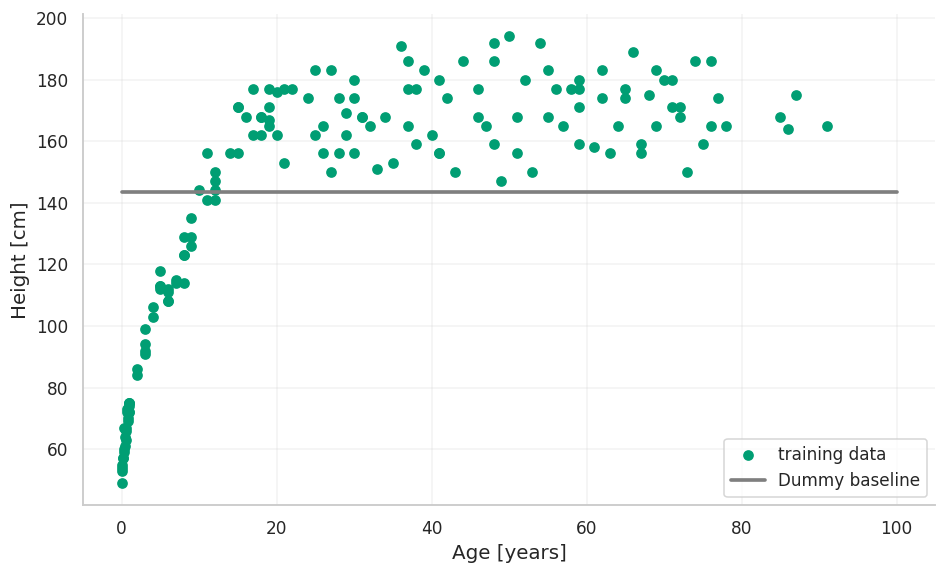

In [22]:
# Visualize the dummy regressor predictions

plt.figure()
plt.scatter(X_train["Age"], y_train, label="training data", color=ALIASES.get("actual", None))
plt.plot(
    X_viz["Age"],
    dummy_regressor.predict(X_viz),
    label="Dummy baseline",
    color=ALIASES.get("dummy", "gray"),
)
plt.xlabel("Age [years]")
plt.ylabel("Height [cm]")
plt.legend(loc="lower right")
plt.show()


**Think.** Why does `DummyRegressor.fit(X_train, y_train)` receive `X_train`, although it does not use it?

<details>
<summary>Answer</summary>

Because scikit-learn uses a consistent estimator API (application programming interface): all prediction models in scikit-learn expose `fit(X, y)`.
The dummy regressor ignores `X` internally but still follows the same interface.

</details>


## Mean squared error

For regression, a common loss is the mean squared error (MSE):

$$
\mathrm{MSE}(y, \hat{y}) = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2
$$

, where $y_i$ is the true target value and $\hat{y}_i$ is the predicted value for the $i$-th example.
Below we compute it manually for the constant baseline.


In [23]:
squared_errors = (y_test.to_numpy() - dummy_predictions_test) ** 2
dummy_mse_manual = squared_errors.mean()
dummy_rmse_manual = np.sqrt(dummy_mse_manual)

manual_table = pd.DataFrame({
    "Actual height": y_test.to_numpy(),
    "Predicted height": dummy_predictions_test,
    "Residual": (y_test.to_numpy() - dummy_predictions_test),
    "Squared error": squared_errors,
})

display(manual_table.head())
print(f"Manual MSE:  {dummy_mse_manual:.2f}")
print(f"Manual RMSE: {dummy_rmse_manual:.2f}")


,Actual height,Predicted height,Residual,Squared error
0,156,143.59,12.41,153.92
1,68,143.59,-75.59,5714.42
2,88,143.59,-55.59,3090.67
3,168,143.59,24.41,595.67
4,165,143.59,21.41,458.23


Manual MSE:  1299.90
Manual RMSE: 36.05


**Check.** What is the unit of MSE here?
<details>
<summary>Answer</summary>
The target variable is measured in centimeters [cm], so MSE is measured in centimeters squared [cm<sup>2</sup>].
</details>

**Check.** What is the unit of RMSE?
<details>
<summary>Answer</summary>
The unit of RMSE is the same as the unit of the target variable, so in this case it is centimeters [cm].
</details>

MSE is implemented in scikit-learn, so we commonly compute it with a function call. For RMSE, we take the square root of MSE.

We can check that the manual and scikit-learn computations give the same result.

In [24]:
from sklearn import metrics
mse_dummy_train = metrics.mean_squared_error(y_train, dummy_regressor.predict(X_train))
print(f"Dummy MSE (train): {mse_dummy_train:.2f}")

mse_dummy_test = metrics.mean_squared_error(y_test, dummy_predictions_test)
print(f"Dummy MSE (test): {mse_dummy_test:.2f}")    


rmse_dummy_train = np.sqrt(mse_dummy_train)
print(f"Dummy RMSE (train): {rmse_dummy_train:.2f}")

rmse_dummy_test = np.sqrt(mse_dummy_test)
print(f"Dummy RMSE (test): {rmse_dummy_test:.2f}")

Dummy MSE (train): 1655.63
Dummy MSE (test): 1299.90
Dummy RMSE (train): 40.69
Dummy RMSE (test): 36.05


## Linear regression

Linear regression is a simple parametric model that fits a linear function to the data.
`LinearRegression` in scikit-learn implements ordinary least squares linear regression, which minimizes the MSE on the training data.

The fitted function is determined by the coefficients and the intercept, which are stored in the `coef_` and `intercept_` attributes of the fitted model, respectively.

**Predict.** Do we expect linear regression to perform better than a simple mean predictor?
<details>
<summary>Answer</summary>
Yes, we expect linear regression to perform better. Age clearly contains information about height, so a model that uses age should
outperform a constant predictor, even if the relationship is not perfectly linear.

In a general case, linear regression should perform at least similarly to the constant predictor if the relationship is very weak or if the data is very noisy.
</details>

**Takeaway.** Linear regression is a good first real model, but it can underfit non-linear relationships.


In [25]:
from sklearn.linear_model import LinearRegression

linear_regressor = LinearRegression()
linear_regressor.fit(X_train, y_train)

linear_predictions_test = linear_regressor.predict(X_test)
heights_test["Linear regression"] = linear_predictions_test

print("Coefficient(s):", linear_regressor.coef_)
print("Intercept:", linear_regressor.intercept_)

rmse_linear_train = np.sqrt(metrics.mean_squared_error(y_train, linear_regressor.predict(X_train)))
rmse_linear_test = np.sqrt(metrics.mean_squared_error(y_test, linear_predictions_test))

print(f"Linear regression RMSE (train): {rmse_linear_train:.2f}")
print(f"Linear regression RMSE (test):  {rmse_linear_test:.2f}")


Coefficient(s): [1.13146632]
Intercept: 108.57027080168498
Linear regression RMSE (train): 28.32
Linear regression RMSE (test):  30.36


**Check.** How many coefficients are there, and why?
<details>
<summary>Answer</summary>
There is one coefficient because we currently use one input feature: `Age`.
In general, the number of coefficients is equal to the number of input features.
</details>

**Check.** How many intercepts are there, and why?
<details>
<summary>Answer</summary>
There is one intercept because we are fitting a linear regression model with an intercept term.
</details>


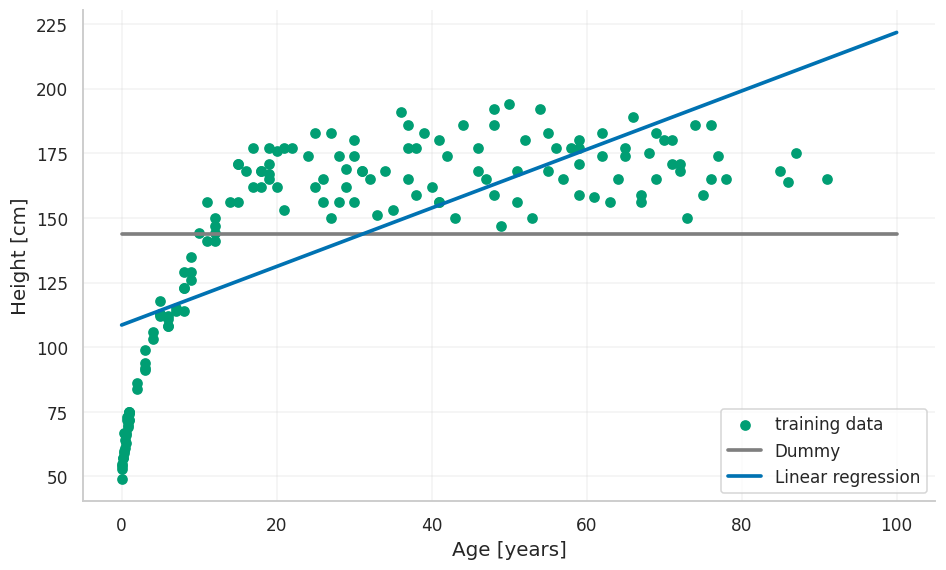

In [26]:
plt.figure()
plt.scatter(X_train["Age"], y_train, label="training data", color=ALIASES.get("actual", None))
plt.plot(
    X_viz["Age"],
    dummy_regressor.predict(X_viz),
    label="Dummy",
    color=ALIASES.get("dummy", "gray"),
)
plt.plot(
    X_viz["Age"],
    linear_regressor.predict(X_viz),
    label="Linear regression",
    color=ALIASES.get("linear", None),
)
plt.xlabel("Age [years]")
plt.ylabel("Height [cm]")
plt.legend(loc="lower right")
plt.show()


## Regression tree

A regression tree is a non-parametric model that fits a piecewise constant function to the data. It belongs to the TDIDT family of models, so it is a decision tree that can be used for regression tasks.

A regression tree is flexible enough to fit very irregular shapes.
The implementation in scikit-learn is `DecisionTreeRegressor`. By default, it is unconstrained, which means that it grows the tree until no split reduces the error anymore.
This means that a regression tree in scikit-learn **overfits by default**.

**Predict.** What do you expect the training RMSE of the default regression tree to look like?

<details>
<summary>Answer</summary>
It should be close to 0, often actually reaching 0, because the default tree is flexible
enough to fit tiny regions of the training data.
</details>

**Takeaway.** A very low training error is not automatically a good sign.


In [27]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

tree_regressor_default = DecisionTreeRegressor(random_state=RANDOM_STATE)
tree_regressor_default.fit(X_train, y_train)

default_tree_train_rmse = np.sqrt(
    metrics.mean_squared_error(y_train, tree_regressor_default.predict(X_train))
)
default_tree_test_rmse = np.sqrt(
    metrics.mean_squared_error(y_test, tree_regressor_default.predict(X_test))
)

print(f"Default tree RMSE (train): {default_tree_train_rmse:.2f}")
print(f"Default tree RMSE (test):  {default_tree_test_rmse:.2f}")


Default tree RMSE (train): 5.50
Default tree RMSE (test):  12.91


**Explain.** Why is RMSE in this case not exactly 0?

<details>
<summary>Answer</summary>
Same input, different target. For example, if you have two people aged 10 with different heights: 130cm and 134cm the model cannot fit both perfectly.

A regression tree predicts the mean in the leaf, so it will predict something like: $\hat{y} = (130 + 134) / 2 = 132$
→ non-zero training error.
</details>




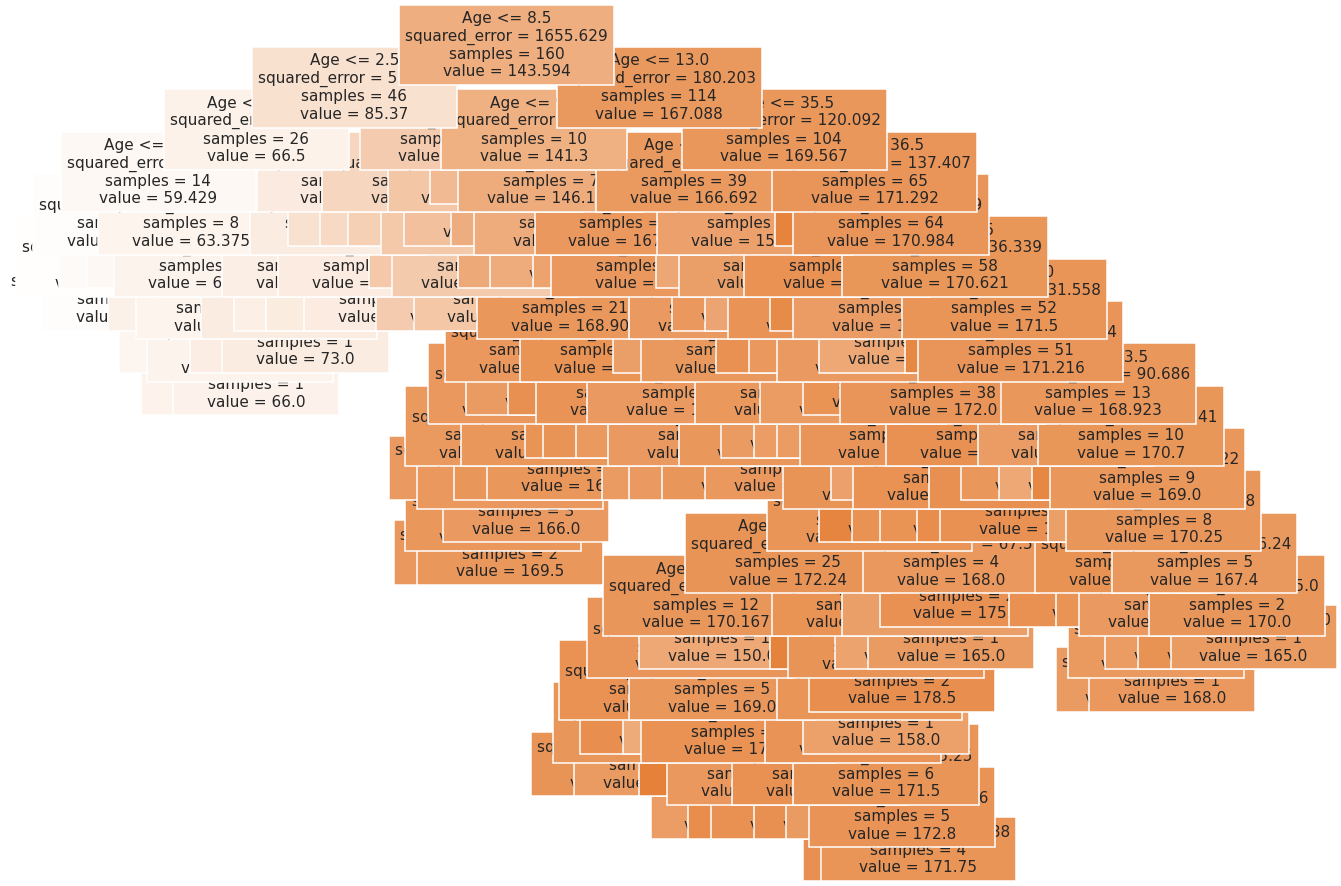

In [28]:
# Visualize the default regression tree

plt.figure(figsize=(14, 10))
plot_tree(
    tree_regressor_default,
    feature_names=feature_cols,
    filled=True,
    fontsize=10,
)
plt.show()


In [29]:
# Number os nodes in the default tree
n_nodes_default = tree_regressor_default.tree_.node_count
print(f"Number of nodes in the default regression tree: {n_nodes_default}")
# Number of leaves in the default tree
n_leaves_default = tree_regressor_default.get_n_leaves()
print(f"Number of leaves in the default regression tree: {n_leaves_default}")   

Number of nodes in the default regression tree: 179
Number of leaves in the default regression tree: 90


The default regression tree is useless as it memorizes the training data, which leads to zero or near-zero training error but very high test error. 

Now let's visualize what that means for predictions.

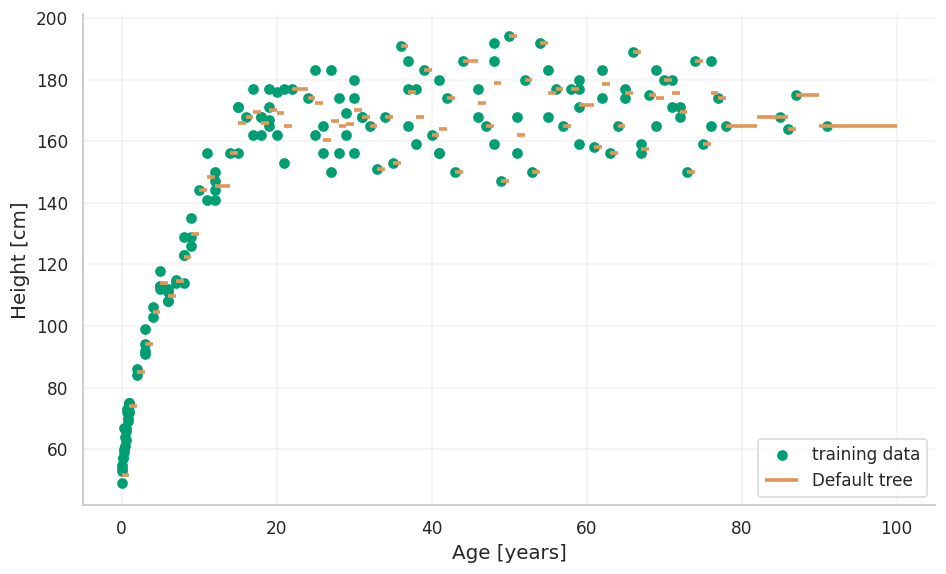

In [30]:
def plot_horizontal_tree_segments(x_values, y_values, *, label, color, linestyle="-", linewidth=2.4):
    x_sorted = np.asarray(x_values).ravel()
    y_sorted = np.asarray(y_values).ravel()

    order = np.argsort(x_sorted)
    x_sorted = x_sorted[order]
    y_sorted = y_sorted[order]

    change_idx = np.where(np.diff(y_sorted) != 0)[0]
    starts = np.r_[0, change_idx + 1]
    ends = np.r_[change_idx, len(x_sorted) - 1]

    for seg_i, (start, end) in enumerate(zip(starts, ends)):
        x_left = x_sorted[start]
        x_right = x_sorted[end + 1] if end + 1 < len(x_sorted) else x_sorted[end]
        plt.hlines(
            y=y_sorted[start],
            xmin=x_left,
            xmax=x_right,
            colors=color,
            linestyles=linestyle,
            linewidth=linewidth,
            label=label if seg_i == 0 else None,
        )

plt.figure()
plt.scatter(X_train["Age"], y_train, label="training data", color=ALIASES.get("actual", None))
plot_horizontal_tree_segments(
    X_viz["Age"],
    tree_regressor_default.predict(X_viz),
    label="Default tree",
    color=pale(ALIASES.get("tree", "#D55E00"), alpha=0.35),
)
plt.xlabel("Age [years]")
plt.ylabel("Height [cm]")
plt.legend(loc="lower right")
plt.show()


### Hyperparameter tuning the regression tree

It is of outmost importance to tune the regression tree. Scikit-learn's `DecisionTreeRegressor` has several hyperparameters that control the growth of the tree, such as `max_depth`, `min_samples_leaf`, and `min_samples_split`. These are pre-pruning hyperparameters that limit the growth of the tree and prevent it from overfitting.

We find the best set of hyperparameters by performing a grid search over a range of values for each hyperparameter. We can use scikit-learn's `GridSearchCV` to automate this process.

`GridSearchCV` uses k-fold cross-validation: The **training** data is split into $k$ folds, creating $k$ sets. For each configuration of hyperparameters, the model is trained on $k-1$ folds and evaluated on the remaining fold. This process is repeated $k$ times, with each fold serving as the validation set once.
The hyperparameters that yield the best performance on the validation set are then selected for the final model, which is trained on the entire training data and evaluated on the test set.


In [31]:
from sklearn.model_selection import GridSearchCV

tree_param_grid = {
    "max_depth": [2, 3, 4, 5, 6, None],
    "min_samples_leaf": [2, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10, 15, 20],
}

tree_grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid=tree_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
)

tree_grid_search.fit(X_train, y_train)

best_tree = tree_grid_search.best_estimator_

print("Best tree parameters:", tree_grid_search.best_params_)

best_tree_train_rmse = np.sqrt(metrics.mean_squared_error(y_train, best_tree.predict(X_train)))
best_tree_test_rmse = np.sqrt(metrics.mean_squared_error(y_test, best_tree.predict(X_test)))

print(f"Tuned tree RMSE (train): {best_tree_train_rmse:.2f}")
print(f"Tuned tree RMSE (test):  {best_tree_test_rmse:.2f}")


Best tree parameters: {'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 2}
Tuned tree RMSE (train): 9.20
Tuned tree RMSE (test):  11.98


**Check.** How many different hyperparameter combinations are there in the grid search above? 

<details>
<summary>Answer</summary>
`max_depth`: 6 values, `min_samples_leaf`: 5 values, and `min_samples_split`: 5 values, so there are $ 6 \times 5 \times 5 = 150 $ different hyperparameter combinations.
</details>

**Check.** How many models were trained? 

<details>
<summary>Answer</summary>
150 $ different hyperparameter combinations times 5 folds in cross-validation means that 750 models were trained during the grid search.
</details>

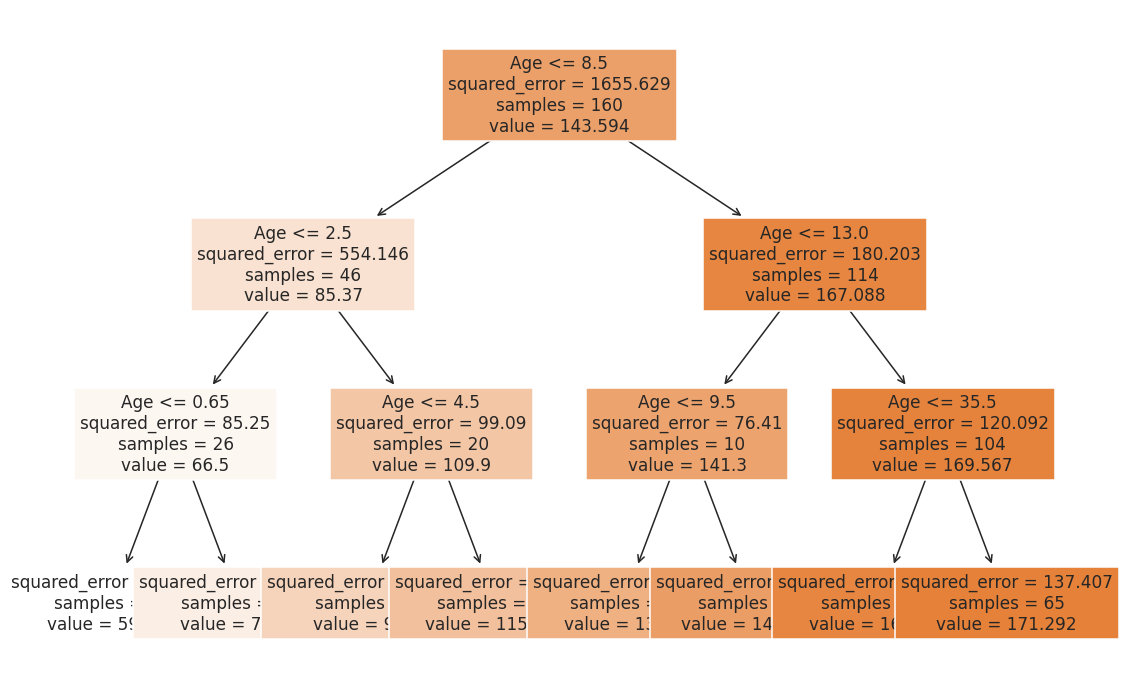

In [32]:
plt.figure(figsize=(12, 8))
plot_tree(
    best_tree,
    feature_names=feature_cols,
    filled=True,
    fontsize=11,
)
plt.show()


**Think.** Why is the tuned tree usually preferable to the default tree, even if its training error is higher?

<details>
<summary>Answer</summary>

Because we care about generalization, not memorization. A tuned tree accepts a somewhat
higher training error in exchange for lower validation/test error.

</details>


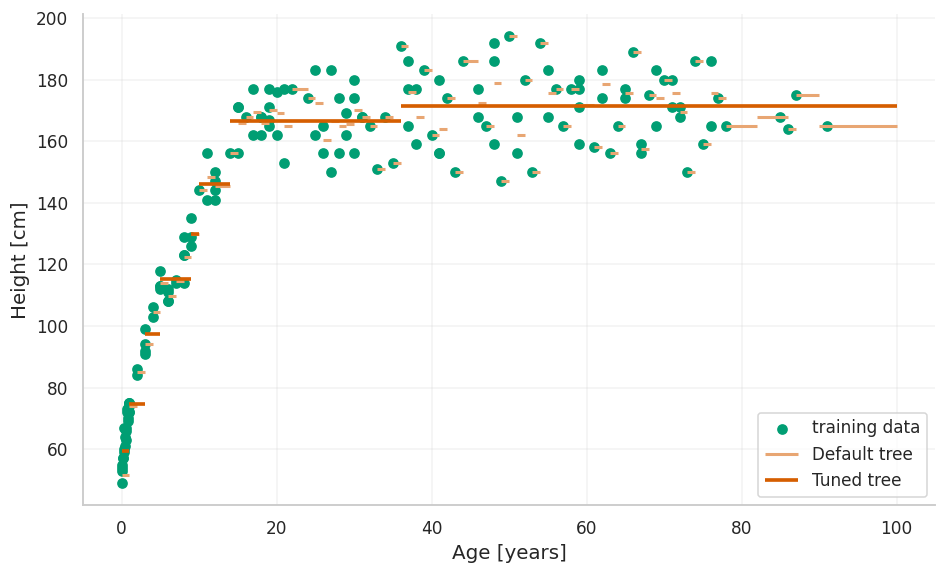

In [33]:
plt.figure()
plt.scatter(X_train["Age"], y_train, label="training data", color=ALIASES.get("actual", None))

plot_horizontal_tree_segments(
    X_viz["Age"],
    tree_regressor_default.predict(X_viz),
    label="Default tree",
    color=pale(ALIASES.get("tree", "#D55E00"), alpha=0.45),
    linestyle="-",
    linewidth=2.0,
)
plot_horizontal_tree_segments(
    X_viz["Age"],
    best_tree.predict(X_viz),
    label="Tuned tree",
    color=ALIASES.get("tree", "#D55E00"),
    linestyle="-",
)

plt.xlabel("Age [years]")
plt.ylabel("Height [cm]")
plt.legend(loc="lower right")
plt.show()


## K-nearest neighbors regression

KNN predicts by averaging nearby `k` training examples.
That makes the choice of `k` a very important hyperparameter. 

The second important hyperparameter is the **distance metric**, which determines what "nearby" means. The default is the Euclidean distance, but other options include Manhattan distance and Minkowski distance.

Anothr important hyperparameter is the **weighting scheme**, which determines how much influence each neighbor has on the prediction. The default is uniform weighting, where all neighbors have equal influence, but other options include distance weighting, where closer neighbors have more influence than farther ones.


In [34]:
from sklearn.neighbors import KNeighborsRegressor

k_initial = 3
knn_regressor = KNeighborsRegressor(n_neighbors=k_initial)
knn_regressor.fit(X_train, y_train)

knn_predictions_test = knn_regressor.predict(X_test)
rmse_knn_initial_test = np.sqrt(metrics.mean_squared_error(y_test, knn_predictions_test))

print(f"KNN-{k_initial} RMSE (test): {rmse_knn_initial_test:.2f}")


KNN-3 RMSE (test): 12.34


**Predict.** What happens when `k` increases?

<details>
<summary>Answer</summary>

Predictions become smoother and more stable. Bias increases, variance decreases.

</details>

**Takeaway.** Small `k` can overfit; large `k` can underfit.


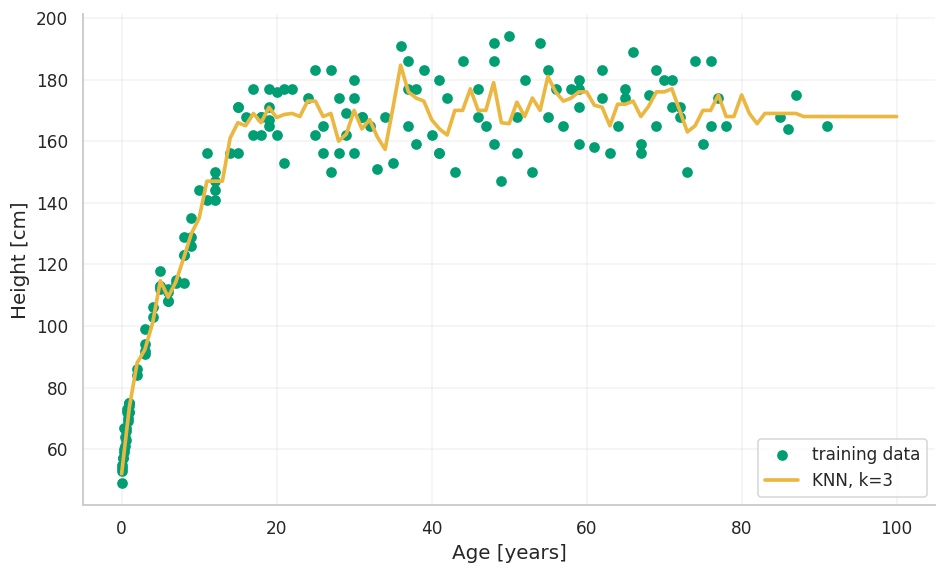

In [35]:
# Visualize KNN predictions, not tuned yet, to show the effect of `k` on the predictions
plt.figure()
plt.scatter(X_train["Age"], y_train, label="training data", color=ALIASES.get("actual", None))
plt.plot(
    X_viz["Age"],
    knn_regressor.predict(X_viz),
    label=f"KNN, k={k_initial}",
    color=pale(ALIASES.get("knn", "#E69F00"), alpha=0.25),
)
plt.xlabel("Age [years]")
plt.ylabel("Height [cm]")
plt.legend(loc="lower right")
plt.show()


### Hyperparameter Tuning KNN


In [36]:
knn_param_grid = {
    "n_neighbors": [1, 3, 5, 7, 9, 11, 13, 15],
    "weights": ["uniform", "distance"],
}

knn_grid_search = GridSearchCV(
    estimator=KNeighborsRegressor(),
    param_grid=knn_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
)

knn_grid_search.fit(X_train, y_train)

best_knn = knn_grid_search.best_estimator_
print("Best KNN parameters:", knn_grid_search.best_params_)

best_knn_train_rmse = np.sqrt(metrics.mean_squared_error(y_train, best_knn.predict(X_train)))
best_knn_test_rmse = np.sqrt(metrics.mean_squared_error(y_test, best_knn.predict(X_test)))

print(f"Tuned KNN RMSE (train): {best_knn_train_rmse:.2f}")
print(f"Tuned KNN RMSE (test):  {best_knn_test_rmse:.2f}")


Best KNN parameters: {'n_neighbors': 13, 'weights': 'uniform'}
Tuned KNN RMSE (train): 9.16
Tuned KNN RMSE (test):  10.79


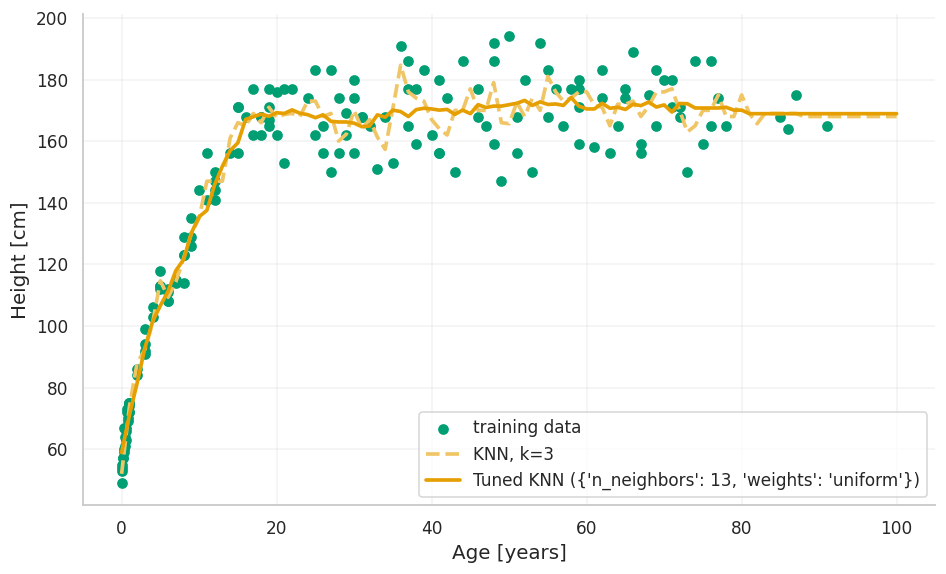

In [37]:
plt.figure()
plt.scatter(X_train["Age"], y_train, label="training data", color=ALIASES.get("actual", None))
plt.plot(
    X_viz["Age"],
    knn_regressor.predict(X_viz),
    label=f"KNN, k={k_initial}",
    color=pale(ALIASES.get("knn", "#E69F00"), alpha=0.4),
    linestyle="--",
)
plt.plot(
    X_viz["Age"],
    best_knn.predict(X_viz),
    label=f"Tuned KNN ({knn_grid_search.best_params_})",
    color=ALIASES.get("knn", "#E69F00"),
)
plt.xlabel("Age [years]")
plt.ylabel("Height [cm]")
plt.legend(loc="lower right")
plt.show()


## Feature transformation: Age $\rightarrow \log_{10}(\mathrm{Age}+1)$

Instead of changing the model, we can change the representation of the input data. This is a common technique in regression, where we often apply transformations to the input features to make the relationship between the inputs and the target more linear.

In this case, the relationship between `Age` and `Height` is non-linear, especially in early childhood. The data exhibits a rapid increase in height during early years, followed by a slower growth rate. The data "bends downwards". A common transformation to handle such non-linear relationships is to apply a logarithmic transformation to the age feature. This can help linear regression capture the rapid growth in height during early years and the slower growth later on.

We therefore fit linear regression once on `Age` and once on `log10(Age + 1)`.
For the logarithmic transformation, we add 1 to `Age` to avoid taking the logarithm of zero, which is undefined. The base of the logarithm can be any positive number, but we commonly use base 10 or the natural logarithm (base $e$). In this case, we use base 10 for better interpretability.


In [38]:
def log_transform(x):
    """Returns the log10 of x + 1 to handle non-linearity and zero values."""
    return np.log10(x + 1)

# We create log-transformed versions of the datasets for training, testing, and visualization. We start by copying the original datasets to avoid modifying them directly.
X_train_log = X_train.copy() 
X_test_log = X_test.copy()
X_viz_log = X_viz.copy()

X_train_log["Age"] = log_transform(X_train_log["Age"])
X_test_log["Age"] = log_transform(X_test_log["Age"])
X_viz_log["Age"] = log_transform(X_viz_log["Age"])

log_linear_regressor = LinearRegression()
log_linear_regressor.fit(X_train_log, y_train)

log_linear_train_rmse = np.sqrt(metrics.mean_squared_error(y_train, log_linear_regressor.predict(X_train_log)))
log_linear_test_rmse = np.sqrt(metrics.mean_squared_error(y_test, log_linear_regressor.predict(X_test_log)))

print(f"Linear regression on Age RMSE (test):      {rmse_linear_test:.2f}")
print(f"Linear regression on log(Age) RMSE (test): {log_linear_test_rmse:.2f}")


Linear regression on Age RMSE (test):      30.36
Linear regression on log(Age) RMSE (test): 18.74


**Check.** Is the transformation learned from the data?
<details>
<summary>Answer</summary>
No. The transformation is chosen by the user based on the shape of the data. This is called a "manual" or "hand-crafted" transformation, and the process of choosing it is often referred to as "feature engineering".
</details>

**Think.** Is the log-transformed model still a linear regression model?
<details>
<summary>Answer</summary>
Yes. It is still linear in its parameters. The nonlinearity comes from transforming the input feature.
</details>

**Think.** What would be a useful transformation if the data "bends upwards" instead of downwards?
<details>
<summary>Answer</summary>
If the data "bends upwards", a common transformation to handle such non-linear relationships is to apply an exponential transformation to the input feature. For example, we could use `exp(Age)` or `Age^2` as the transformed feature when predicting income from Age.
</details>



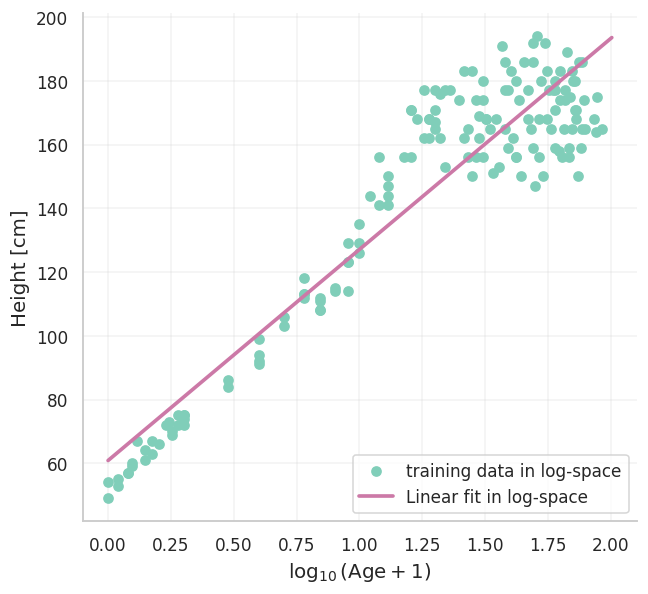

In [39]:
# 
plt.figure(figsize=(6.5, 6))

plt.scatter(
    X_train_log["Age"],
    y_train,
    label="training data in log-space",
    color=pale(ALIASES.get("actual", None), alpha=0.5),
)
plt.plot(
    X_viz_log["Age"],
    log_linear_regressor.predict(X_viz_log),
    label="Linear fit in log-space",
    color=ALIASES.get("linear_log", "#CC79A7"),
)
plt.xlabel(r"$\log_{10}(\mathrm{Age}+1)$")
plt.ylabel("Height [cm]")
plt.legend(loc="lower right")
plt.show()


The plot above shows **what the transformed data and the fitted line look like in the transformed space**.

### Pipelines
When we transform features (e.g. using $\log(\text{Age})$), we must apply the **same transformation** at training, prediction, and application time (deployment). 

Scikit-learn’s `Pipeline` ensures that preprocessing and modeling are applied consistently. In our case, we can define a pipeline that:
1. transforms the input (log transformation), and
2. fits a linear regression model on the transformed data.

This way, calling `.fit()` applies the transformation to the training data, and `.predict()` automatically applies the same transformation to new data before making predictions.

Pipelines are also necessary for proper **hyperparameter tuning**: when used with cross-validation, all transformations are learned on the training folds only and applied correctly to validation folds. It is further useful for comparing different transformations and models: we can define multiple pipelines with different transformations and compare their performance in a systematic way on the same dataset.

A Pipeline requires transformers with `.fit()` and `.transform()`. `FunctionTransformer` lets us turn a simple function into a valid preprocessing step.

In [40]:
# Pipeline of log transformation and regression

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

log_linear_pipeline = Pipeline([
    ("log", FunctionTransformer(log_transform, validate=False)),   # validate=False because we are applying it to a DataFrame, not a numpy array
    ("linear", LinearRegression()),
])

log_linear_pipeline.fit(X_train, y_train)

#RMSE of the pipeline model on the test set
log_linear_pipeline_train_rmse = np.sqrt(metrics.mean_squared_error(y_train, log_linear_pipeline.predict(X_train)))
print(f"Pipeline (log + linear regression) RMSE (train): {log_linear_pipeline_train_rmse:.2f}")


Pipeline (log + linear regression) RMSE (train): 14.33


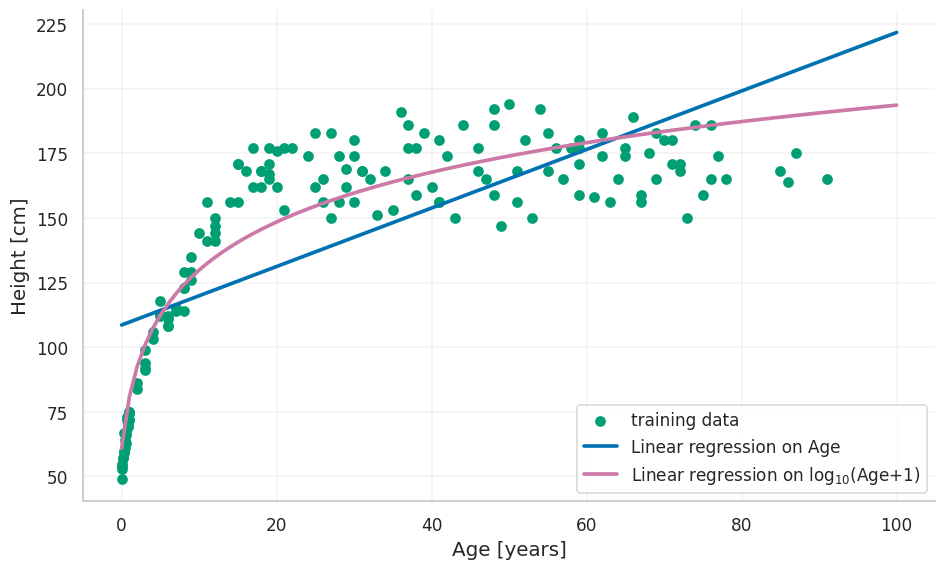

In [41]:
# Plot the linear and log-linear regression predictions in the original age space for comparison
plt.figure()
plt.scatter(X_train["Age"], y_train, label="training data", color=ALIASES.get("actual", None))
plt.plot(
    X_viz["Age"],
    linear_regressor.predict(X_viz),
    label="Linear regression on Age",
    color=ALIASES.get("linear", None),
)
plt.plot(
    X_viz["Age"],
    log_linear_pipeline.predict(X_viz),
    label="Linear regression on log$_{10}$(Age+1)",
    color=ALIASES.get("linear_log", "#CC79A7"),
)
plt.xlabel("Age [years]")
plt.ylabel("Height [cm]")
plt.legend(loc="lower right")
plt.show()


**Remember.** Why do we need pipelines?

<details> <summary>Answer</summary>
Pipelines ensure that the same transformations are applied consistently during training and prediction, and they allow us to include preprocessing steps in the model selection process when using cross-validation.
</details>

## Polynomial regression
Polynomial regression is a special case of feature transformation, where we create new features by taking powers of the original input features. For example, if we have an input feature `Age`, we can create new features `Age^2`, `Age^3`, etc. By including these polynomial features in our linear regression model, we can fit more complex, non-linear relationships between the input and the target. In case we have more input features, we can also create interaction terms by multiplying different features together (e.g., `Age * Income`). If we have dummy variables, we can also create interaction terms between the original features and the dummy variables (e.g., `Age * Gender`), which allows us to capture different relationships for different groups in the data.

Polynomial regression is implemented as **feature expansion plus linear regression**.
In scikit-learn, we can use `PolynomialFeatures` to create the polynomial features, and then fit a linear regression model on the expanded feature set. The degree of the polynomial is a hyperparameter that controls the flexibility of the model: a degree of 1 corresponds to linear regression, while higher degrees allow for more complex relationships. However, increasing the degree also increases the risk of overfitting, so it is important to tune this hyperparameter carefully.

We use **pipelines** to chain the polynomial feature expansion and the linear regression model together, which allows us to treat the entire process as a single estimator that can be fitted and evaluated in the same way as any other model.


In [42]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

polynomial_pipeline = Pipeline([
    ("poly", PolynomialFeatures(include_bias=False)),
    ("scaler", StandardScaler()),
    ("linear_regression", LinearRegression()),
])


**Predict.** What do you expect as the degree becomes very large?

<details>
<summary>Answer</summary>

The fitted curve becomes more flexible and may start oscillating strongly, especially near
the boundaries of the data range.

</details>


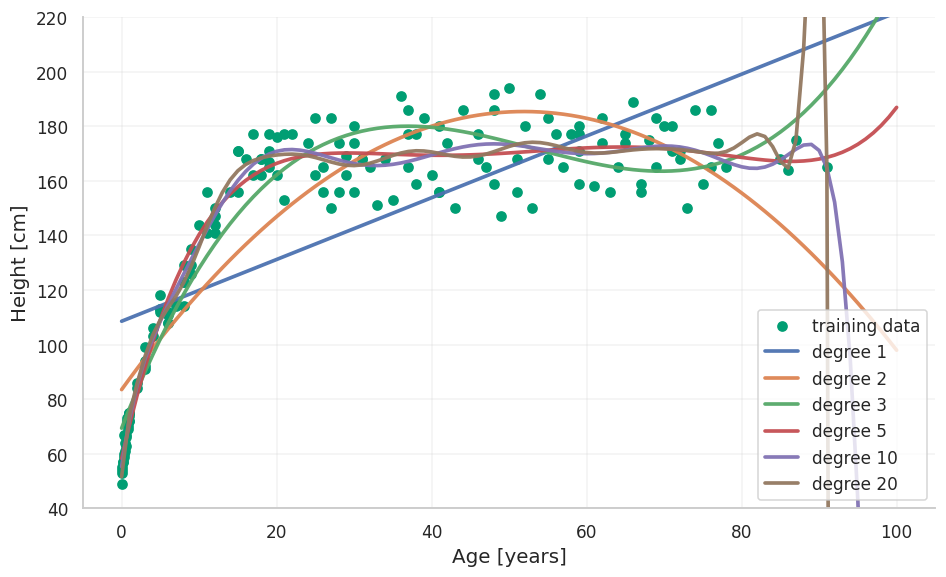

In [43]:
# Visualize the polynomial regression predictions fotten on the training data for different degrees in the original age space
plt.figure()
plt.scatter(X_train["Age"], y_train, label="training data", color=ALIASES.get("actual", None))

polynomial_degrees = [1, 2, 3, 5, 10, 20]

for i, degree in enumerate(polynomial_degrees):
    polynomial_pipeline.set_params(poly__degree=degree)
    polynomial_pipeline.fit(X_train, y_train)
    plt.plot(
        X_viz["Age"],
        polynomial_pipeline.predict(X_viz),
        label=f"degree {degree}",
        alpha=0.95,
    )
# Limit the y-axis to focus on the relevant range of heights
plt.ylim(40, 220)
plt.xlabel("Age [years]")
plt.ylabel("Height [cm]")
plt.legend(loc="lower right")
plt.show()


**Predict.** Which polynomial degree appears to best capture the overall trend of the data?
<details> <summary>Answer</summary>
Degrees 3–5 appear to best capture the underlying relationship:
They follow the rapid growth at early ages,
they model the plateau in adulthood,
they remain relatively smooth.
</details>

**Identify.** Which models are underfitting? Which are overfitting?
<details> <summary>Answer</summary>
Underfitting: degree 1 and degree 2 are too simple, cannot capture curvature.
Overfitting: degree 10 and especially degree 20 exhibit strong oscillations, especially near boundaries.
Good balance: degree 3–5.
</details>

**Think.** Why do high-degree polynomials behave erratically near the edges (e.g. age > 80)?
<details> <summary>Answer</summary>
High-degree polynomials are very flexible and try to fit all training points closely. Near the boundaries:
there are fewer data points, small changes in coefficients lead to large changes in predictions.
This leads to unstable extrapolation and oscillations.
</details>

### Hyperparameter tuning the polynomial degree

In [44]:
polynomial_param_grid = {
    "poly__degree": list(range(1, 16))
}

polynomial_grid_search = GridSearchCV(
    estimator=polynomial_pipeline,
    param_grid=polynomial_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
)

polynomial_grid_search.fit(X_train, y_train)

# Print a table of all the polynomial degrees and their corresponding mean cross-validated RMSE scores and variance scores
cv_results = pd.DataFrame(polynomial_grid_search.cv_results_)
cv_results["mean_test_rmse"] = -cv_results["mean_test_score"]
cv_results["std_test_rmse"] = cv_results["std_test_score"]
cv_results = cv_results[["param_poly__degree", "mean_test_rmse", "std_test_rmse"]]
cv_results.columns = ["Polynomial degree", "Mean CV RMSE", "Std CV RMSE"]
display(cv_results)

best_poly_pipeline = polynomial_grid_search.best_estimator_
best_degree = polynomial_grid_search.best_params_["poly__degree"]


best_poly_train_rmse = np.sqrt(metrics.mean_squared_error(y_train, best_poly_pipeline.predict(X_train)))
best_poly_test_rmse = np.sqrt(metrics.mean_squared_error(y_test, best_poly_pipeline.predict(X_test)))

print("Best polynomial degree:", best_degree)
print(f"Tuned polynomial RMSE (train): {best_poly_train_rmse:.2f}")
print(f"Tuned polynomial RMSE (test):  {best_poly_test_rmse:.2f}")


,Polynomial degree,Mean CV RMSE,Std CV RMSE
0,1,28.56,1.85
1,2,18.46,1.63
2,3,12.78,1.30
3,4,10.12,0.99
4,5,9.71,0.72
5,6,10.01,0.97
6,7,9.77,0.68
7,8,10.25,1.22
8,9,13.56,7.80
9,10,10.33,1.76


Best polynomial degree: 5
Tuned polynomial RMSE (train): 9.48
Tuned polynomial RMSE (test):  12.03


## Train vs test error

At the end, we are not interested in the training error, but in the test error, which is a better estimate of the generalization performance of the model. It is an estimate on how well the model will perform on unseen data, which is what we ultimately care about.

We compare the training and test errors of all hyperparameter tuned models on different metrics.

In [45]:
import pandas as pd
from sklearn import metrics

# The models were already defined and fitted in the previous cells, so we can directly use them here to compute the predictions and evaluate the metrics.
models = {
    "Dummy": dummy_regressor, 
    "Linear regression": linear_regressor,
    "Regression tree": best_tree,
    "KNN regressor": best_knn,
    "Log-linear regression": log_linear_pipeline,
    "Polynomial regression": best_poly_pipeline
}

metric_fns = {
    "Max error": metrics.max_error,
    "MSE": metrics.mean_squared_error,
    "RMSE": lambda y_true, y_pred: np.sqrt(metrics.mean_squared_error(y_true, y_pred)),
    "MAE": metrics.mean_absolute_error,
    "R2": metrics.r2_score,
    "Median absolute error": metrics.median_absolute_error,
    "Explained variance": metrics.explained_variance_score,
    "MAPE": metrics.mean_absolute_percentage_error,
}

train_results = {model_name: {} for model_name in models.keys()}
test_results = {model_name: {} for model_name in models.keys()}

for model_name, model in models.items():
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    for metric_name, metric_fn in metric_fns.items():
        train_results[model_name][metric_name] = metric_fn(y_train, y_pred_train)
        test_results[model_name][metric_name] = metric_fn(y_test, y_pred_test)

df_train = pd.DataFrame(train_results).T
df_test = pd.DataFrame(test_results).T

pd.options.display.float_format = "{:.2f}".format

print("Training set performance:")
display(df_train)
print("\nTest set performance:")
display(df_test)

Training set performance:


,Max error,MSE,RMSE,MAE,R2,Median absolute error,Explained variance,MAPE
Dummy,94.59,1655.63,40.69,34.05,0.00,30.41,0.00,0.34
Linear regression,59.57,802.20,28.32,23.73,0.52,22.72,0.52,0.21
Regression tree,24.29,84.71,9.20,7.32,0.95,5.73,0.95,0.05
KNN regressor,24.38,83.91,9.16,7.11,0.95,5.50,0.95,0.05
Log-linear regression,34.64,205.48,14.33,11.61,0.88,8.82,0.88,0.08
Polynomial regression,23.76,89.90,9.48,7.54,0.95,5.66,0.95,0.05



Test set performance:


,Max error,MSE,RMSE,MAE,R2,Median absolute error,Explained variance,MAPE
Dummy,77.59,1299.90,36.05,29.69,-0.06,24.41,0.00,0.25
Linear regression,55.54,921.81,30.36,25.57,0.25,24.95,0.32,0.19
Regression tree,25.31,143.58,11.98,10.31,0.88,9.00,0.88,0.07
KNN regressor,25.77,116.47,10.79,8.77,0.91,6.96,0.91,0.06
Log-linear regression,39.02,351.29,18.74,14.65,0.71,10.68,0.73,0.09
Polynomial regression,25.04,144.80,12.03,9.94,0.88,9.79,0.88,0.06


MAPE is the mean absolute percentage error, which is a common metric for regression tasks. MAPE expresses the error as a percentage of the true values, which can be more relevant in some contexts: a small absolute error may be more significant for small true values than for large true values, and MAPE captures this relative error.

**Check.** What is the unit of measurement for each of the error metrics?

<details> <summary>Answer</summary>

- Max error: centimeters [cm]
- MSE: centimeters squared [cm<sup>2</sup>]
- RMSE: centimeters [cm]
- MAE: centimeters [cm]
- R2: unitless (it is a ratio of variances)
- MedianAE: centimeters [cm]
- Explained variance: unitless (it is a ratio of variances)
- MAPE: percentage [%]

</details>

### Compare all regressors on the same plot


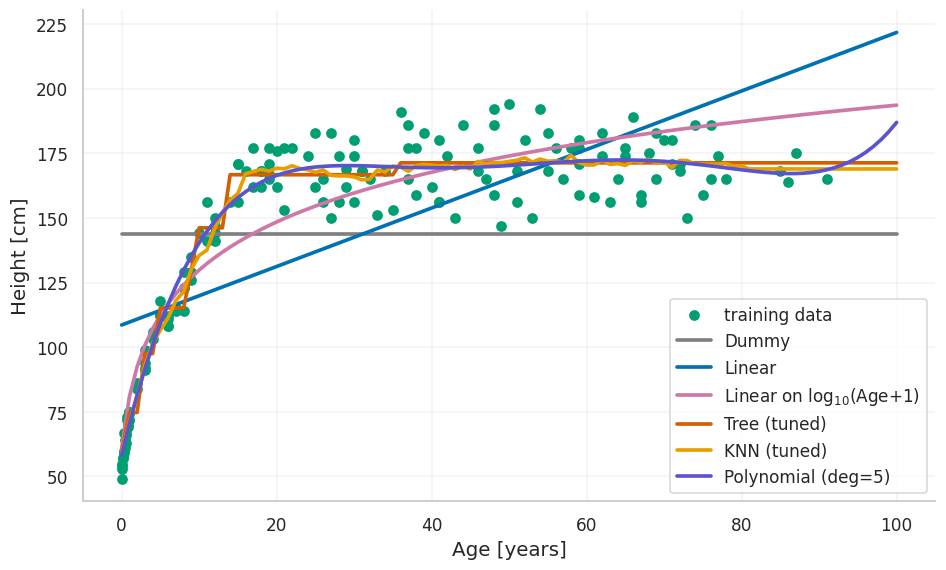

In [46]:
plt.figure()
plt.scatter(X_train["Age"], y_train, label="training data", color=ALIASES.get("actual", None))
plt.plot(X_viz["Age"], dummy_regressor.predict(X_viz), label="Dummy", color=ALIASES.get("dummy", "gray"))
plt.plot(X_viz["Age"], linear_regressor.predict(X_viz), label="Linear", color=ALIASES.get("linear", None))
plt.plot(X_viz["Age"], log_linear_regressor.predict(X_viz_log), label="Linear on log$_{10}$(Age+1)", color=ALIASES.get("linear_log", "#CC79A7"))
plt.plot(X_viz["Age"], best_tree.predict(X_viz), label="Tree (tuned)", color=ALIASES.get("tree", "#D55E00"))
plt.plot(X_viz["Age"], best_knn.predict(X_viz), label="KNN (tuned)", color=ALIASES.get("knn", "#E69F00"))
plt.plot(X_viz["Age"], best_poly_pipeline.predict(X_viz), label=f"Polynomial (deg={best_degree})", color=ALIASES.get("poly", "#009E73"))
plt.xlabel("Age [years]")
plt.ylabel("Height [cm]")
plt.legend(loc="lower right")
plt.show()


**Think.** Which model would you choose based on the error metrics and the plot?

<details>
<summary>Answer</summary>
KNN outperforms the other models in terms of most performance metrics. Together with the decision tree, it captures the non-linear relationship between Age and Height.

All regression-based models (linear, log-linear, and polynomial) perform worse than KNN and the tuned tree, with polynomial regression being the best among them.  All regression-based models extrapolate to +- infinity (look at the plots at Age>88). 
</details>


## Mixed numeric and categorical features in practice

We now add a binary categorical feature from the dataset and handle it with a proper preprocessing pipeline.
This section is practical rather than theoretical: it shows how to combine numeric and categorical data safely in scikit-learn.


In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

X_age_gender = df[["Age", "Gender"]]
y_height = df["Height"]

X_train_mix, X_test_mix, y_train_mix, y_test_mix = train_test_split(
    X_age_gender, y_height, test_size=0.2, random_state=RANDOM_STATE
)

X_train_mix.head()

,Age,Gender
79,17.00,M
197,86.00,F
38,5.00,M
24,1.00,F
122,38.00,F


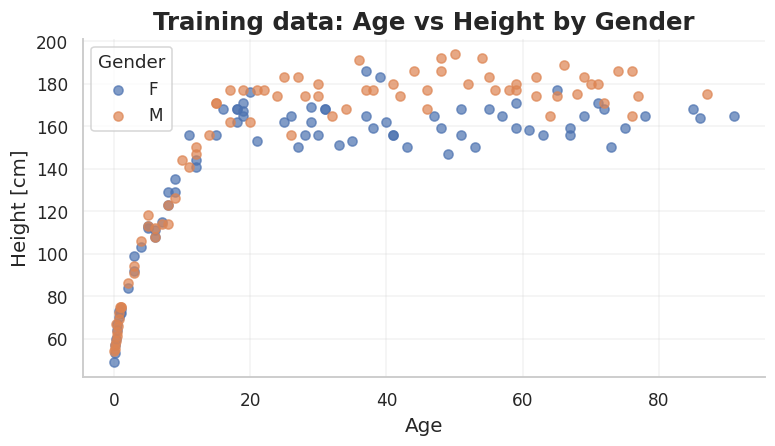

In [48]:
# Plot the training data according to the gender and age, using different colors
plt.figure(figsize=(8, 4))

for gender, group in X_train_mix.join(y_train_mix).groupby("Gender"):
    plt.scatter(
        group["Age"],
        group["Height"],
        label=gender,
        alpha=0.7
    )

plt.xlabel("Age")
plt.ylabel("Height [cm]")
plt.title("Training data: Age vs Height by Gender")
plt.legend(title="Gender")
plt.grid(True)
plt.show()

In [ ]:


preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), ["Age"]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["Gender"]),
    ]
)

age_gender_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", KNeighborsRegressor()),
])

age_gender_param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 13, 15],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2],
}

age_gender_grid_search = GridSearchCV(
    age_gender_pipeline,
    param_grid=age_gender_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
)

age_gender_grid_search.fit(X_train_mix, y_train_mix)

best_age_gender_knn = age_gender_grid_search.best_estimator_
rmse_age_gender_test = np.sqrt(
    metrics.mean_squared_error(y_test_mix, best_age_gender_knn.predict(X_test_mix))
)

print("Best parameters:", age_gender_grid_search.best_params_)
print(f"KNN with Age + Gender RMSE (test): {rmse_age_gender_test:.2f}")


Best parameters: {'model__n_neighbors': 15, 'model__p': 2, 'model__weights': 'distance'}
KNN with Age + Gender RMSE (test): 8.61


: 

**Check.** Why are `OneHotEncoder` and `StandardScaler` placed inside the pipeline?

<details>
<summary>Answer</summary>

To avoid data leakage: Preprocessing should be fitted only on the training data inside the model-selection workflow.
The pipeline ensures that the same fitted preprocessing is applied consistently during cross-validation and testing.

</details>


## Takeaways

- The constant predictor is basic regression baseline.
- Evaluation of regression models is done through metrics like MSE, RMSE, MAE, R2, and MAPE.
- Linear regression is a useful first model, but feature transformations can help.
- Hyperparameter tuning (through crossvalidation on the training set) is a necessary step in many model families, including, KNN, trees, polynomial regression.
- Polynomial regression is linear regression on expanded features, the degree of the polynomial is a hyperparameter that controls the flexibility of the model and needs to be tuned.
- Pipelines are essential once preprocessing must learned and/or applied consistently to training and test (and application) data.
